# بخش 1: تحلیل مجموعه داده

In [2]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent / 'src'))

import numpy as np

from data_utils import (
    load_synthetic_data, split_train_test, normalize_data,
    create_sequences, TimeSeriesDataset, get_dataloaders
)
from plotting import (
    plot_time_series, plot_all_features, plot_correlation_heatmap,
    save_table, ensure_dir, RESULT_DIR, plot_correlation_heatmap_with_lag
)


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
np.random.seed(42)
data_path=None
train_ratio=0.8
seq_length=10
plot_start=0
plot_end=1000
target_series_name="01_target_series"
all_features_name="feature"
correlation_heatmap_name="03_correlation_heatmap"


In [4]:
# Load data
data = load_synthetic_data(data_path)

# Split data
train_data, test_data = split_train_test(data, train_ratio)
print("\nOriginal Data statistics:")
print(f"Mean of training data: {np.mean([train_data[f] for f in ['x1','x2','x3','x4','x5','y']]):.6f}")
print(f"Std of training data: {np.std([train_data[f] for f in ['x1','x2','x3','x4','x5','y']]):.6f}")

# Normalize
train_norm, test_norm, stats = normalize_data(train_data, test_data)

print("\nData normalization statistics:")
print(f"Mean of normalized training data: {np.mean([train_norm[f] for f in ['x1','x2','x3','x4','x5','y']]):.6f}")
print(f"Std of normalized training data: {np.std([train_norm[f] for f in ['x1','x2','x3','x4','x5','y']]):.6f}")


Original Data statistics:
Mean of training data: -0.277019
Std of training data: 1.752074

Data normalization statistics:
Mean of normalized training data: -0.000000
Std of normalized training data: 1.000000


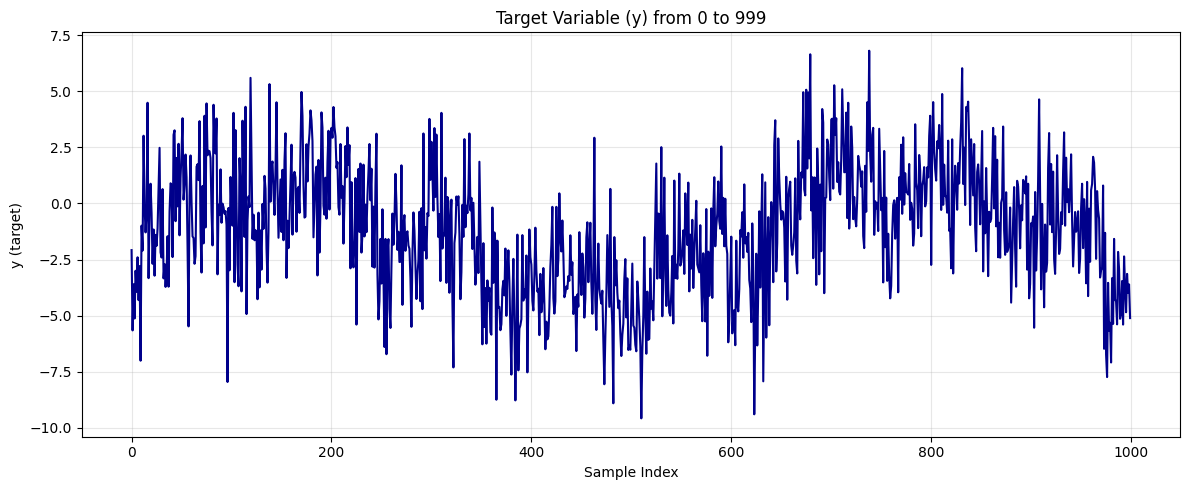

Target series plot saved as: 01_target_series


In [5]:
y = data['y']
fig1 = plot_time_series(
    y, 
    start_idx=plot_start, 
    end_idx=plot_end,
    title="Target Variable (y)",
    save_name=target_series_name
)
print(f"Target series plot saved as: {target_series_name}")

1-1 ﺗﻤﺎﻡ ﭘﻨﺞ ﻣﺘﻐﻴﺮ ﻭﺭﻭﺩﯼ  x1ﺗﺎ  x5ﻭ ﻫﻤﭽﻨﻴﻦ ﻫﺪﻑ  yﺭﺍ ﺩﺭ ﻧﻤﻮﺩﺍﺭ ﻫﺎﯼ ﻣﺠﺰﺍ ﺗﺮﺳﻴﻢ ﻛﻨﻴﺪ(ﺟﻤﻌﺎ ۶ ﻧﻤﻮﺩﺍﺭ).

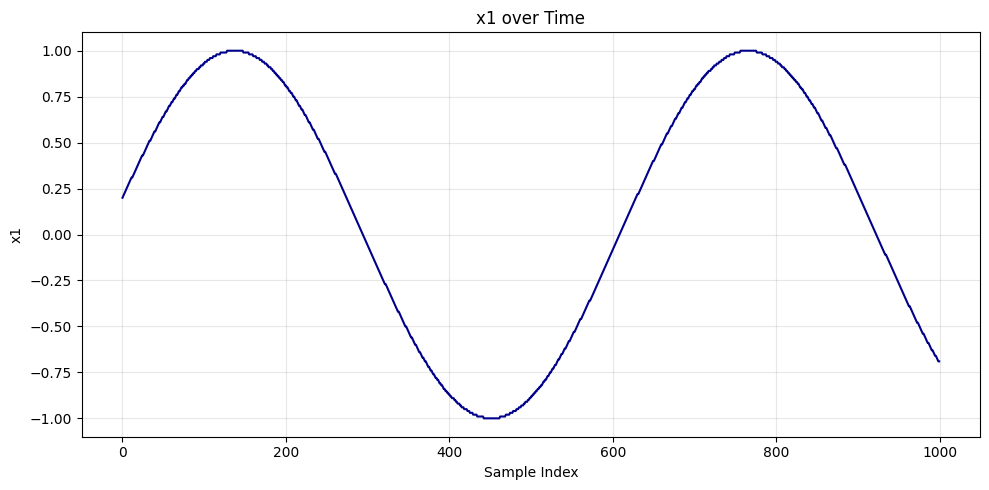

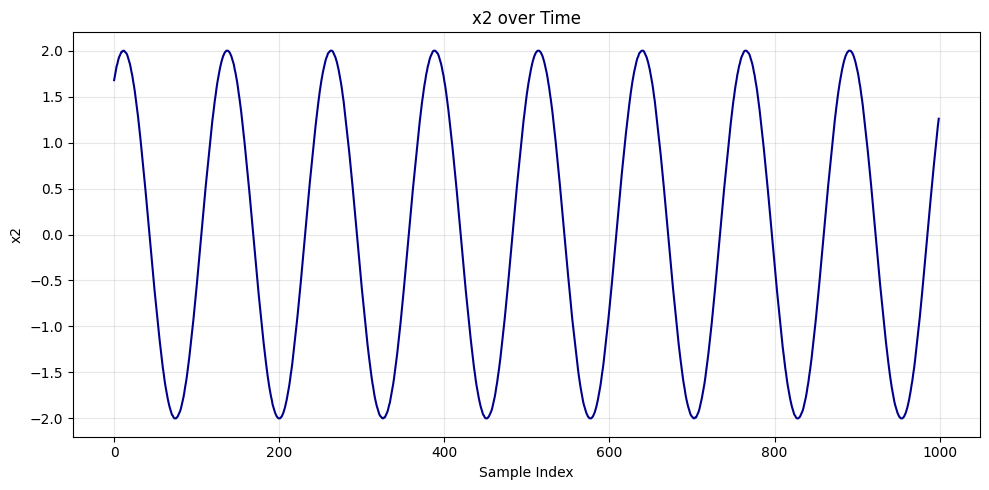

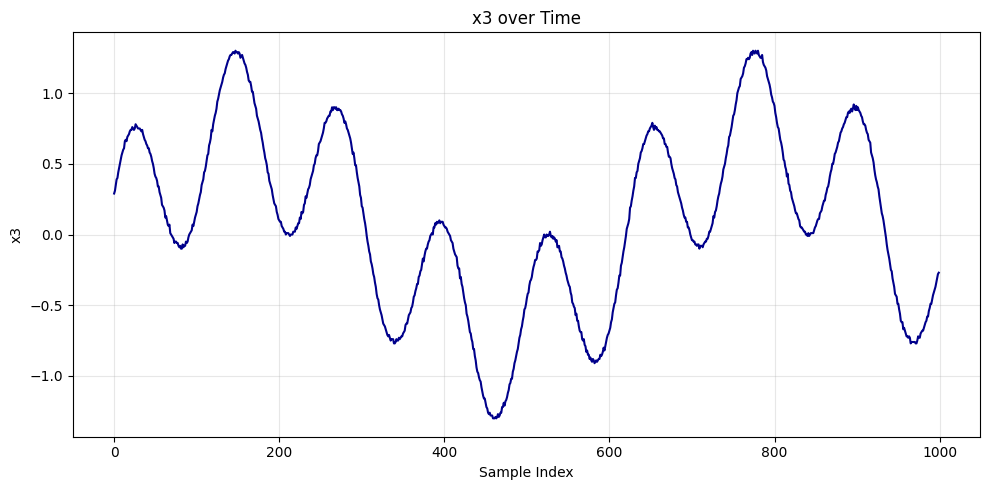

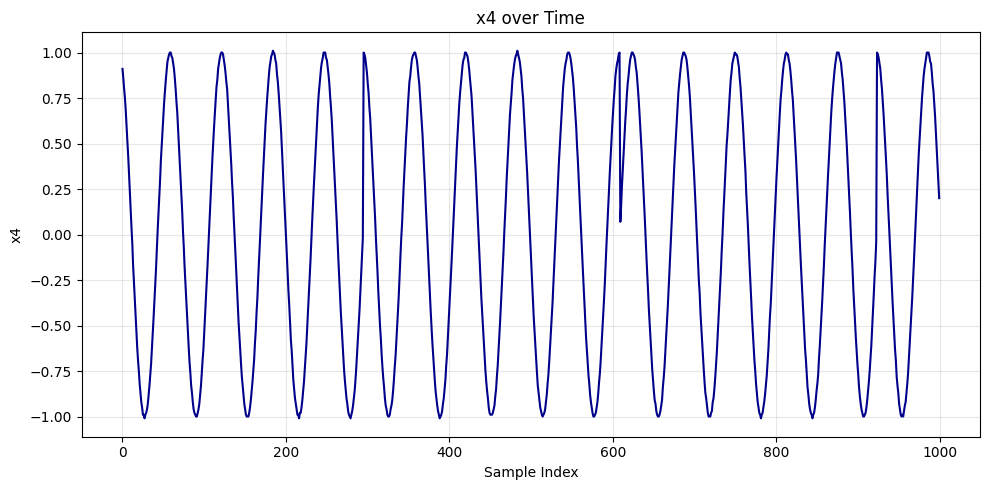

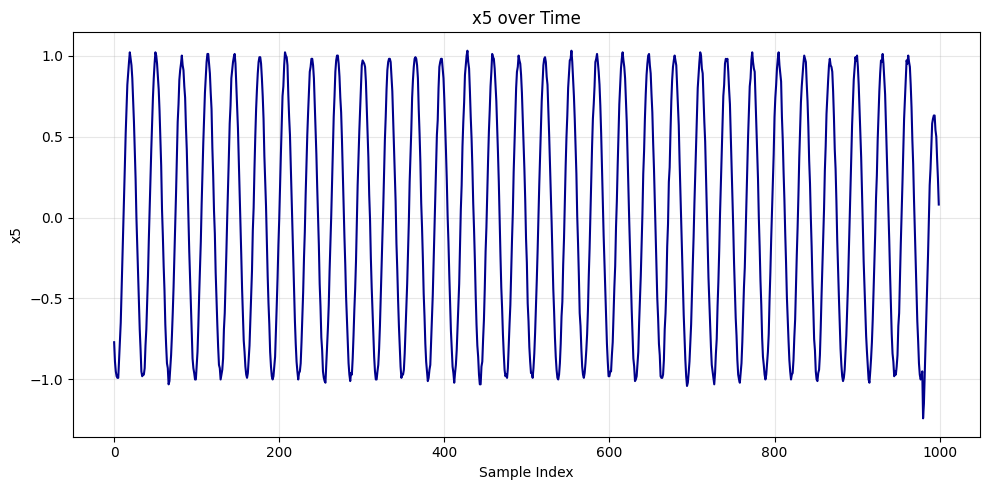

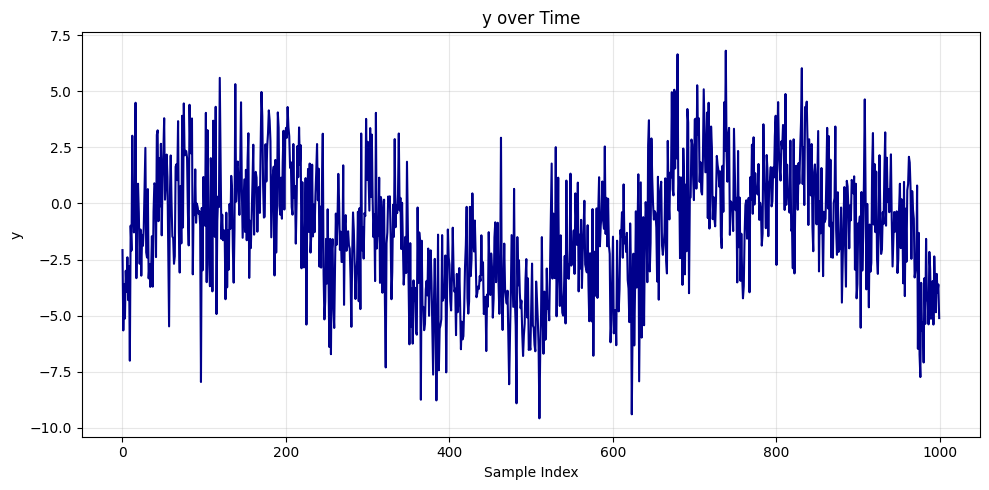

All features plot saved as: feature


In [6]:
fig2 = plot_all_features(
    data,
    start_idx=plot_start,
    end_idx=plot_end,
    save_name=all_features_name
)
print(f"All features plot saved as: {all_features_name}")

1-2 ﻣﺎﺗﺮیس ﻫﻤﺒﺴﺘﮕﯽ ﺑﻴﻦ x1,...,x5 ﻭ y ﺭﺍ ﻣﺤﺎﺳﺒﻪ ﻭ ﺑﻪ ﺻﻮﺭﺕ ﻧﻘﺸﻪ ﺣﺮﺍﺭﺗﯽ(heatmap) ﻧﻤﺎﻳﺶ ﺩﻫﻴﺪ.

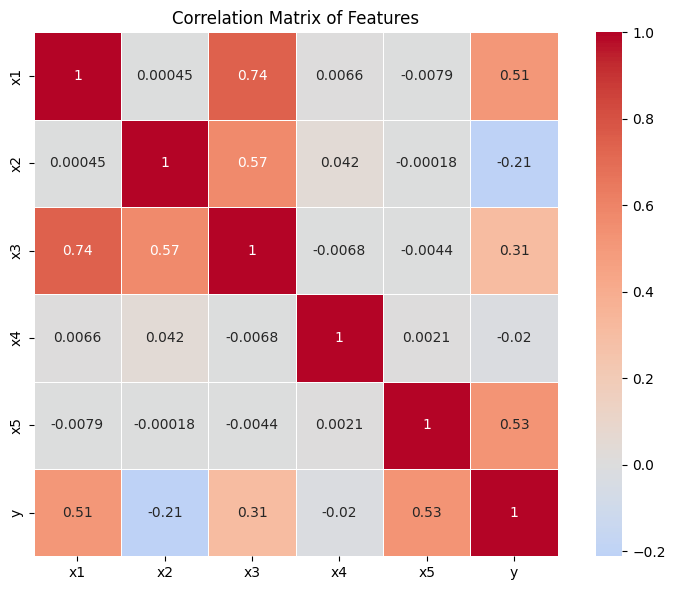

Correlation heatmap saved as: 03_correlation_heatmap


In [7]:
fig3, corr_matrix = plot_correlation_heatmap(
    data,
    save_name=correlation_heatmap_name
)
print(f"Correlation heatmap saved as: {correlation_heatmap_name}")